# Day 24: Places and their names



## Data processing

In [1]:
#setup
import requests
import pandas as pd
import os
import configparser
import geopandas as gpd
from shapely.geometry import Point

In [2]:
#set filepaths
project_root = os.path.abspath(os.getcwd())
root = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
config_file =  os.path.join(root, 'config.cfg')

# geodata for shapefiles
config = configparser.ConfigParser()
config.read(config_file)
gdata_root = config['geodata']['path']

In [4]:
#Get data from OSM via overpass api
overpass_url = "http://overpass-api.de/api/interpreter"

overpass_query = """
[out:json];
area["ISO3166-1"="GB"][admin_level=2]->.searchArea;
way["highway"]["name"~"Prince Andrew"](area.searchArea);
out center;
"""
response = requests.get(overpass_url, params={'data': overpass_query})
data = response.json()

In [5]:
#convert json into dataframe
df_dict = {"id":[], "lat":[], "lon": [], "name":[]}

for element in data['elements']:
    df_dict["id"].append(element["id"])
    for tag in ["name"]:
        try:
            df_dict[tag].append(element["tags"][tag])
        except KeyError:
            df_dict[tag].append("") 
    if element["type"]=="node":
        df_dict["lat"].append(element["lat"])
        df_dict["lon"].append(element["lon"])
    else:
        df_dict["lat"].append(element["center"]["lat"])
        df_dict["lon"].append(element["center"]["lon"])
        
df = pd.DataFrame.from_dict(df_dict)

In [6]:
#remove duplicate nodes for the same way (IDs via manual checks)
streets_keep  = [25119460, 28861851, 29017459, 31821056, 53274441, 53274443,
                62195125, 76502676, 89048375, 91499758, 113524262, 118646948,
                152346580, 308972224, 823387079, 1042960736, 1316186384
                ]

df = df[df["id"].isin(streets_keep)].reset_index(drop=True)

In [7]:
#extract suffix of street name (street, road, close, etc)
df["type"] = df["name"].str.split(" ").str[-1]
df["type"].value_counts()

type
Close       4
Road        4
Drive       3
Crescent    2
Way         2
Grove       1
Park        1
Name: count, dtype: int64

In [8]:
# convert into geodataframe
geometry = [Point(xy) for xy in zip(df['lon'].astype(float), df['lat'].astype(float))]
gdf = gpd.GeoDataFrame(df, crs = 'EPSG:4326', geometry = geometry)
gdf.head()

,id,lat,lon,name,type,geometry
0,25119460,52.045681,-0.019600,Prince Andrew's Close,Close,POINT (-0.01960 52.04568)
1,28861851,51.371654,1.424730,Prince Andrew Road,Road,POINT (1.42473 51.37165)
2,29017459,52.405872,-2.026031,Prince Andrew Crescent,Crescent,POINT (-2.02603 52.40587)
3,31821056,53.463196,-2.763096,Prince Andrew Grove,Grove,POINT (-2.76310 53.46320)
4,53274441,52.663255,1.276228,Prince Andrews Close,Close,POINT (1.27623 52.66325)


<Axes: >

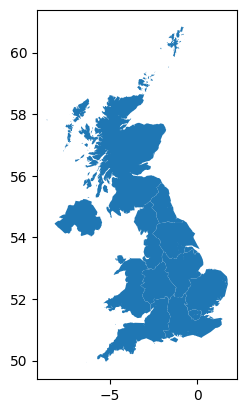

In [9]:
#get UK shapefile
uk_gdf = gpd.GeoDataFrame.from_file(os.path.join(gdata_root, 'uk-regions\\uk_regions.geojson'))
uk_gdf = uk_gdf.to_crs(4326)
uk_gdf.plot()

## Visualisation

In [10]:
from pypalettes import load_cmap
from pyfonts import load_google_font
import matplotlib.pyplot as plt

font_r = load_google_font("Open Sans", weight="regular" )
font_title = load_google_font("Questrial")
font_subtitle = load_google_font("Bentham")

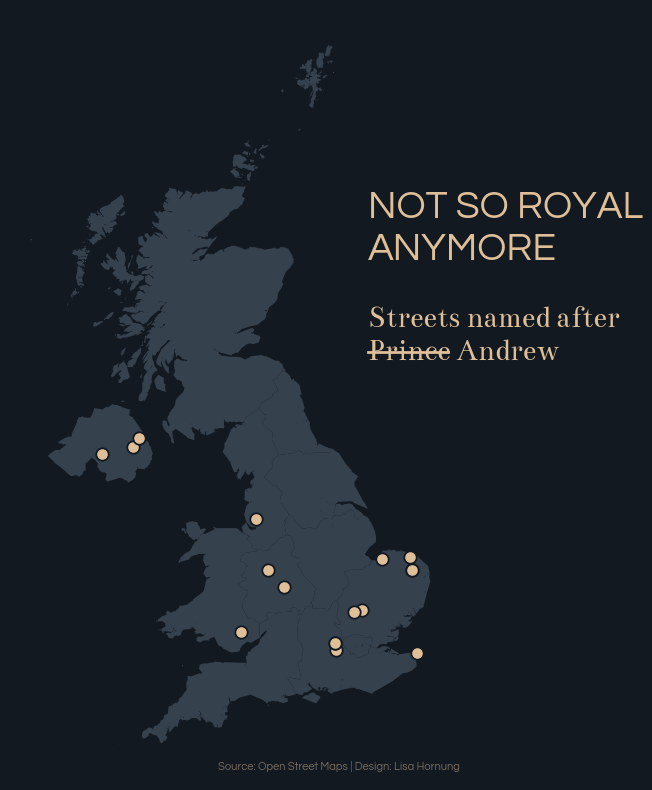

In [37]:
fig, ax = plt.subplots(figsize=(10,10))
fig.set_facecolor("#121921")

#plot data
uk_gdf.plot(ax=ax, color="#36414E")
gdf.plot(ax=ax, color="#DFBF98", edgecolor="#121921", linewidth=1.3, markersize=80)
ax.axis("off")

#title
def strike(text):
    return ''.join([c + '\u0336' for c in text])

fig.text(0.65,0.6 +0.03, "Not so royal\nanymore".upper(), font=font_title, color="#DFBF98", fontsize=28)
fig.text(0.65,0.5+0.03, "Streets named after\nPrince Andrew", font=font_subtitle, color="#DFBF98", fontsize=22)
fig.text(0.5,0.12, "Source: Open Street Maps | Design: Lisa Hornung", font=font_title, color="#DFBF98", fontsize=8, alpha=0.5)

#strike through
fig.lines.append(plt.Line2D([0.65, 0.73], [0.508+0.03, 0.508+0.03], 
                            zorder=1, transform=fig.transFigure, color="#DFBF98", linewidth=2))

#export
plt.savefig("prince-andrew-streets.svg")
plt.savefig("prince-andrew-streets.png", bbox_inches='tight', pad_inches=0.45, dpi=300)

## Playground

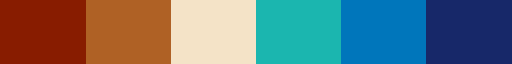

In [55]:
#test classed colours
cmap = load_cmap("Coconut", cmap_type="discrete")
color_map = {'Close': cmap.hex[0], 'Road':cmap.hex[1], 'Drive': cmap.hex[3],
                 'Crescent':cmap.hex[4], 'Way':cmap.hex[5], 'Grove': '#666666',
                  'Park': '#666666' }

gdf["color"] = gdf["type"].map(color_map)